# SHAP Dependence Plot

**Family:** Machine learning &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Machine learning:* Evaluate and explain fitted models: classification performance, calibration, learning curves, residuals, feature importance and feature effects.

## Design purpose

One dot per prediction. The x-axis is a feature's value and the y-axis is how much that value pushed the prediction up or down (its SHAP contribution). Color is a second feature. The shape of the cloud shows the effect, and a color split that fans out shows an interaction: the effect of one feature depends on another.

## When to use

- Show the shape of one feature's effect in a model (linear, threshold, saturating)
- Detect and explain interactions, e.g. utilization hurts more when income is low
- Follow up on a SHAP summary plot for the top features

## Avoid when

- Readers will interpret contributions as causal effects (they describe the model, not the world)
- Features are strongly correlated (attributions get split arbitrarily between them)
- Only the overall importance ranking is needed (use permutation importance or a SHAP summary)

## Alternatives

- Partial dependence / ICE plot
- 2-D partial dependence plot
- SHAP summary (beeswarm)

## Design tips

- Choose the color feature that best explains vertical spread (shap's `approximate_interactions` does this)
- Add a zero line and the feature's distribution as a rug or histogram
- For tree models use the shap package (TreeExplainer); this example computes exact values in closed form

## Example

A simulated credit-default model: logistic regression on credit utilization, income and debt-to-income, plus a utilization × income interaction term. For this model the exact interventional SHAP values have a closed form. For a main effect, φ_j = b_j(x_j − μ_j). For the product term b·x₁x₂, each of the two features receives ½·b·(x_k − μ_k)(x_other + μ_other). No shap package is needed.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from matplotlib.colors import LinearSegmentedColormap
from sklearn.linear_model import LogisticRegression

### Data

In [2]:
rng = np.random.default_rng(17)
n = 3000
df = pd.DataFrame({
    "utilization": rng.beta(2, 3, n) * 100,                  # % of credit limit used
    "income": np.exp(rng.normal(np.log(60), 0.45, n)),       # $k per year
    "dti": rng.uniform(5, 45, n),                            # debt-to-income, %
})
z = (df - df.mean()) / df.std()
true_logit = -2.2 + 1.0 * z["utilization"] - 0.6 * z["income"] + 0.5 * z["dti"] \
    - 0.6 * z["utilization"] * z["income"]
df["default"] = rng.random(n) < 1 / (1 + np.exp(-true_logit))

# Fit: main effects on standardized features + one interaction column
X = z.assign(util_x_income=z["utilization"] * z["income"])
model = LogisticRegression(C=100, max_iter=2000).fit(X, df["default"])
b = dict(zip(X.columns, model.coef_[0]))
mu = z.mean()

# Exact interventional SHAP values on the log-odds scale (closed form for this model)
shap = pd.DataFrame({
    f: b[f] * (z[f] - mu[f]) for f in ["utilization", "income", "dti"]})
shap["utilization"] += 0.5 * b["util_x_income"] * (z["utilization"] - mu["utilization"]) * (z["income"] + mu["income"])
shap["income"] += 0.5 * b["util_x_income"] * (z["income"] - mu["income"]) * (z["utilization"] + mu["utilization"])
pd.Series(b).round(2)

utilization      1.09
income          -0.55
dti              0.42
util_x_income   -0.51
dtype: float64

### Plot

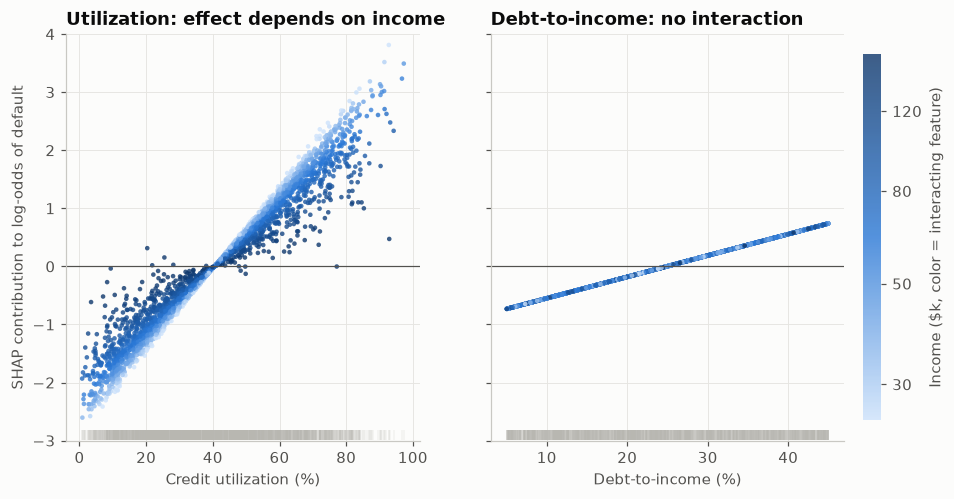

In [3]:
cmap = LinearSegmentedColormap.from_list("income", ["#cde2fb", "#2a78d6", "#0d366b"])
order = np.argsort(rng.random(n))                          # random draw order: no color sits on top
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
for ax, feat, label in [(axes[0], "utilization", "Credit utilization (%)"),
                        (axes[1], "dti", "Debt-to-income (%)")]:
    sc = ax.scatter(df[feat].values[order], shap[feat].values[order], c=df["income"].values[order],
                    cmap=cmap, s=9, alpha=0.8, linewidth=0, norm=plt.matplotlib.colors.LogNorm(25, 160))
    ax.axhline(0, color="#52514e", linewidth=0.8)
    ax.set_xlabel(label)
    # rug of the feature's distribution
    ax.plot(df[feat], np.full(n, -2.9), "|", color="#b8b7b1",
            markersize=6, alpha=0.15)
axes[0].set_ylabel("SHAP contribution to log-odds of default")
axes[0].set_title("Utilization: effect depends on income", fontsize=11.5)
axes[1].set_title("Debt-to-income: no interaction", fontsize=11.5)
axes[0].set_ylim(-3, 4)
cb = fig.colorbar(sc, ax=axes, pad=0.02, shrink=0.9)
cb.set_label("Income ($k, color = interacting feature)")
cb.outline.set_visible(False)
cb.ax.minorticks_off()
cb.set_ticks([30, 50, 80, 120])
cb.set_ticklabels(["30", "50", "80", "120"])
plt.show()

## How to read it

Left: higher utilization raises default risk (contribution rises left to right), but the dots fan out by color. For low-income borrowers (light) the slope is steep, for high-income borrowers (dark) it is shallow, which is the interaction. Right: debt-to-income has a plain linear effect, with no color pattern, so it does not interact with income.

---
Standalone script: [`shap_dependence.py`](shap_dependence.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)